# 10 · Team and player ratings

Three rating systems, each documented as a *methodology*, not an objective
truth:

1. **Elo** for teams (built in notebook 09): how strong is each club going
   into a match?
2. **Expected threat (xT)**: how much did a pass or carry increase the
   chance of a goal?
3. **BIPR**, the Barça Individual Player Rating: a position-specific
   0-100 composite per player-season, with a per-match rating on a familiar
   3-10 scale.

Code: `barca.analytics.xt`, `barca.analytics.ratings`; built by
`barca features`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca.analytics import ratings, xt
from barca.data import store
from barca.visualization import pitch as vp
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(1)

player_ratings = store.features("player_ratings")
pm = store.features("player_match")
grid = store.features("xt_grid")

## 1. Team strength recap

End-of-season Elo for the top of the table in three seasons, the input the
match models use for opponent quality:

In [2]:
rated = store.features("elo")
from barca.features import elo as elo_mod  # noqa: E402

long = elo_mod.long_ratings(rated)
end = long.group_by("season", "team").agg(pl.col("elo_post").last().alias("elo")).sort("elo", descending=True)
pl.concat(
    [end.filter(pl.col("season") == s).head(4).with_columns(pl.int_range(1, 5).alias("rank")) for s in
     ["2008/2009", "2015/2016", "2020/2021"]]
).pivot(on="season", index="rank", values="team")

rank,2008/2009,2015/2016,2020/2021
i64,str,str,str
1,"""Barcelona""","""Barcelona""","""Barcelona"""
2,"""Real Madrid""","""Real Madrid""","""Real Madrid"""
3,"""Sevilla""","""Atlético Madrid""","""Atlético Madrid"""
4,"""Villarreal""","""Athletic Club""","""Sevilla"""


## 2. Expected threat

The xT grid is fitted on every open-play pass, carry and shot of La Liga
2015/16 (all 20 clubs), solving

$$ xT(z) = s(z)\,g(z) + m(z)\sum_{z'} T(z \to z')\,xT(z') $$

where $s$ is the probability of shooting from cell $z$, $g$ the average xG
of those shots, $m$ the probability of moving the ball and $T$ where
successful moves end.

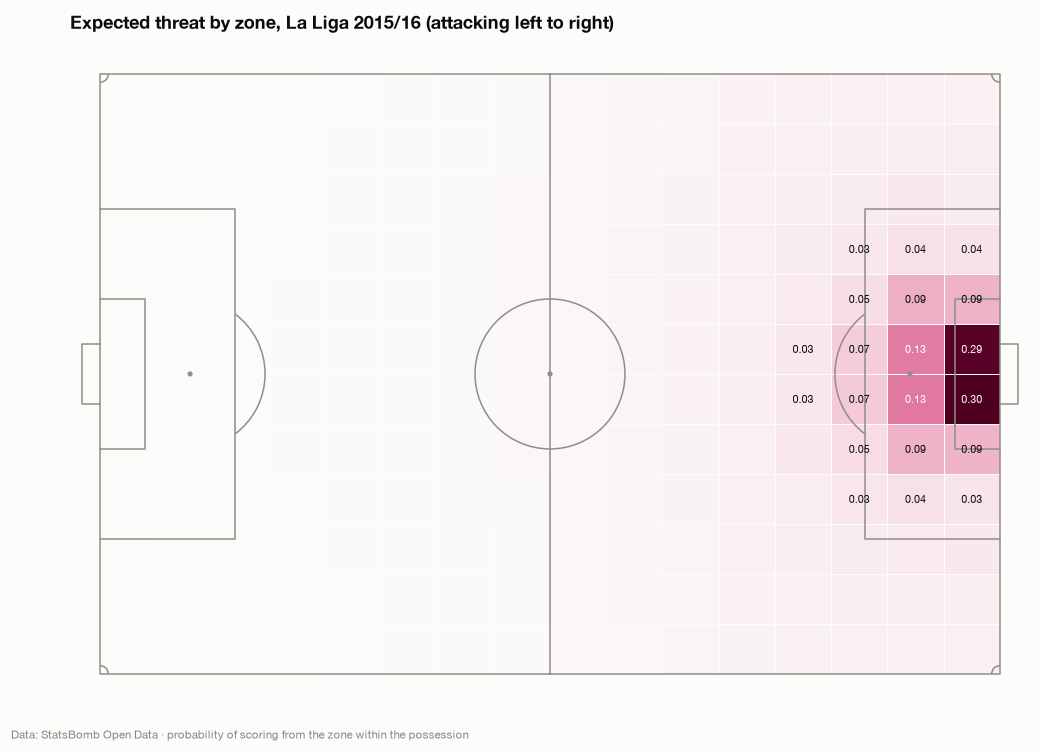

In [3]:
values = np.zeros((xt.NX, xt.NY))
for ix, iy, v in grid.select("ix", "iy", "xt").iter_rows():
    values[ix, iy] = v
p = vp.pitch(line_zorder=2, line_color="#8f8e88")
fig, ax = p.draw(figsize=(10, 6.6))
stats_ = p.bin_statistic(np.array([0.0]), np.array([0.0]), statistic="count", bins=(xt.NX, xt.NY))
stats_["statistic"] = values.T
p.heatmap(stats_, ax=ax, cmap=style.HEAT, edgecolors=style.SURFACE, linewidth=0.5, zorder=1)
for iy in range(xt.NY):
    for ix in range(xt.NX):
        if values[ix, iy] >= 0.03:
            ax.text((ix + 0.5) * 120 / xt.NX, (iy + 0.5) * 80 / xt.NY, f"{values[ix, iy]:.2f}", ha="center",
                    va="center", fontsize=7, color="white" if values[ix, iy] > 0.1 else style.INK, zorder=3)
ax.set_title("Expected threat by zone, La Liga 2015/16 (attacking left to right)")
style.caption(ax, style.STATSBOMB_CREDIT + " · probability of scoring from the zone within the possession")
style.savefig(fig, "10_xt_grid")
plt.show()

Threat is negligible in a team's own half (< 0.01), rises steadily through
midfield and explodes in front of goal: about 0.3 in the central cells
closest to the six-yard box. A pass from midfield to the edge of the box
earns roughly +0.05. Crosses from the by-line to the penalty spot earn far
more.

xT added per 90 for Barcelona players (career, ≥ 3,000 minutes):

In [4]:
career = ratings.aggregate(pm.filter(pl.col("team") == "Barcelona"), ["player_id"])
pl.Config.set_float_precision(3)
career.filter(pl.col("minutes") >= 3000).select(
    "display_name", "position_family", "minutes", "xt_p90", "xt_pass_p90", "xt_carry_p90",
).sort("xt_p90", descending=True).head(12)

display_name,position_family,minutes,xt_p90,xt_pass_p90,xt_carry_p90
str,str,f64,f64,f64,f64
"""Lionel Messi""","""AM""",44342.033,0.398,0.184,0.215
"""Neymar""","""AM""",9720.900,0.373,0.168,0.205
"""Ronaldinho""","""AM""",5095.617,0.307,0.189,0.119
"""Dani Alves""","""FB""",19702.833,0.300,0.225,0.076
"""Ousmane Dembélé""","""AM""",4323.800,0.274,0.114,0.160
"""Cesc Fàbregas""","""MF""",5759.417,0.242,0.155,0.086
"""Andrés Iniesta""","""MF""",24551.217,0.235,0.143,0.092
"""Philippe Coutinho""","""AM""",3769.033,0.202,0.082,0.120
"""Xavi""","""MF""",21158.633,0.193,0.139,0.054


Messi generates the most threat per 90 (≈ 0.40), and more than half of it
by **carrying** the ball, which is exactly what key passes and assists
miss. Neymar is close behind with the same carry-heavy profile. Dani Alves
is the only defender in the top group, adding threat from wide. Busquets
adds about 0.10 per 90: his value (the first pass under pressure) shows up
only modestly, because xT rewards moving the ball *into* dangerous zones,
not keeping it.

## 3. BIPR: method

**Pillars.** Each pillar averages the percentiles of a few per-90 metrics
(defensive metrics possession-adjusted, D-013), within the player's position
family:

In [5]:
pl.DataFrame(
    [{"pillar": k, "metrics": ", ".join(f"{'−' if s < 0 else ''}{m}" for m, s in v)} for k, v in ratings.PILLARS.items()]
)

pillar,metrics
str,str
"""passing""","""passes_completed_p90, pass_com…"
"""creation""","""xa_p90, key_passes_p90, box_en…"
"""progression""","""progressive_passes_p90, progre…"
"""carrying""","""progressive_carries_p90, dribb…"
"""defending""","""padj_tackles_p90, padj_interce…"
"""shooting""","""npxg_p90, shots_p90, touches_i…"
"""security""","""−turnovers_p90, pass_completio…"


**Reference population.** Percentiles are taken against every outfield
player-season with ≥ 900 minutes in La Liga 2015/16, the one season with
every club. Barcelona players from other seasons are rated against the same
fixed population, so ratings are comparable across seasons.

**Weights by position family.** A centre-back is not judged on shooting:

In [6]:
pl.Config.set_float_precision(2)
pl.DataFrame([{"family": f, **w} for f, w in ratings.WEIGHTS.items()])

family,defending,passing,progression,security,carrying,creation,shooting
str,f64,f64,f64,f64,f64,f64,f64
"""CB""",0.35,0.25,0.20,0.10,0.05,0.05,0.00
"""FB""",0.25,0.15,0.20,0.10,0.10,0.20,0.00
"""MF""",0.20,0.25,0.20,0.10,0.05,0.15,0.05
"""AM""",0.05,0.10,0.15,0.05,0.20,0.25,0.20
"""FW""",0.05,0.10,0.10,0.05,0.10,0.20,0.40


**Overall** is the weighted mean of the pillars (0-100). `overall_pct`
additionally ranks it within the reference population. Goalkeepers are not
rated: shot-stopping needs post-shot xG, which the open data does not have.

## 4. The ratings

In [7]:
pl.Config.set_float_precision(1)
reliable = player_ratings.filter(pl.col("rating_reliable"), pl.col("overall").is_not_null())
reliable.filter(pl.col("season") == "2015/2016").group_by("position_family").agg(
    pl.len().alias("player_seasons"), pl.col("overall").mean().alias("mean"),
    pl.col("overall").quantile(0.1).alias("p10"), pl.col("overall").quantile(0.9).alias("p90"),
    pl.col("overall").max().alias("max"),
).sort("position_family")

position_family,player_seasons,mean,p10,p90,max
str,u32,f64,f64,f64,f64
"""AM""",84,50.0,30.9,71.8,90.5
"""CB""",62,50.0,31.5,71.6,83.6
"""FB""",66,50.0,32.5,71.7,84.0
"""FW""",42,50.0,33.3,71.7,87.8
"""MF""",66,50.0,30.3,72.1,82.0


In the reference season the overall score averages about 50 in every
position family and spans roughly 30 to 72 between the 10th and 90th
percentiles.

Best Barcelona player-seasons, one per player. A leaderboard uses a higher
bar (≥ 1,500 minutes) than the 900 needed for a rating to be shown at all,
so that a strong half-season does not top the list.

In [8]:
cols = ["season", "display_name", "position_family", "minutes", "overall", "pillar_passing", "pillar_creation",
        "pillar_progression", "pillar_carrying", "pillar_defending", "pillar_shooting", "pillar_security"]
(
    reliable.filter(pl.col("team") == "Barcelona", pl.col("minutes") >= 1500).sort("overall", descending=True)
    .group_by("display_name", maintain_order=True).first().head(15).select(cols)
)

season,display_name,position_family,minutes,overall,pillar_passing,pillar_creation,pillar_progression,pillar_carrying,pillar_defending,pillar_shooting,pillar_security
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2011/2012""","""Lionel Messi""","""FW""",3406.6,94.8,100.0,100.0,100.0,100.0,56.7,98.2,53.6
"""2006/2007""","""Samuel Eto'o""","""FW""",1544.8,89.7,88.7,98.2,90.5,94.4,51.4,94.6,45.2
"""2015/2016""","""Neymar""","""AM""",3163.1,89.6,89.3,97.9,87.1,99.0,36.5,96.7,42.3
"""2015/2016""","""Luis Suárez""","""FW""",3272.6,86.6,69.0,95.8,85.3,81.3,47.4,97.0,53.6
"""2011/2012""","""Thiago Alcântara""","""MF""",1931.9,86.1,97.3,88.3,95.5,96.5,73.9,89.0,53.8
"""2011/2012""","""Dani Alves""","""FB""",2732.4,86.0,98.1,98.9,98.5,97.5,68.5,94.7,49.2
"""2006/2007""","""Ronaldinho""","""AM""",2076.0,84.4,87.2,93.8,88.9,89.7,18.8,88.7,45.2
"""2015/2016""","""Javier Mascherano""","""CB""",2802.7,83.6,98.4,93.1,98.7,89.5,65.6,10.1,71.8
"""2008/2009""","""Andrés Iniesta""","""AM""",1909.3,83.4,98.5,89.9,95.6,92.5,49.0,58.0,83.3


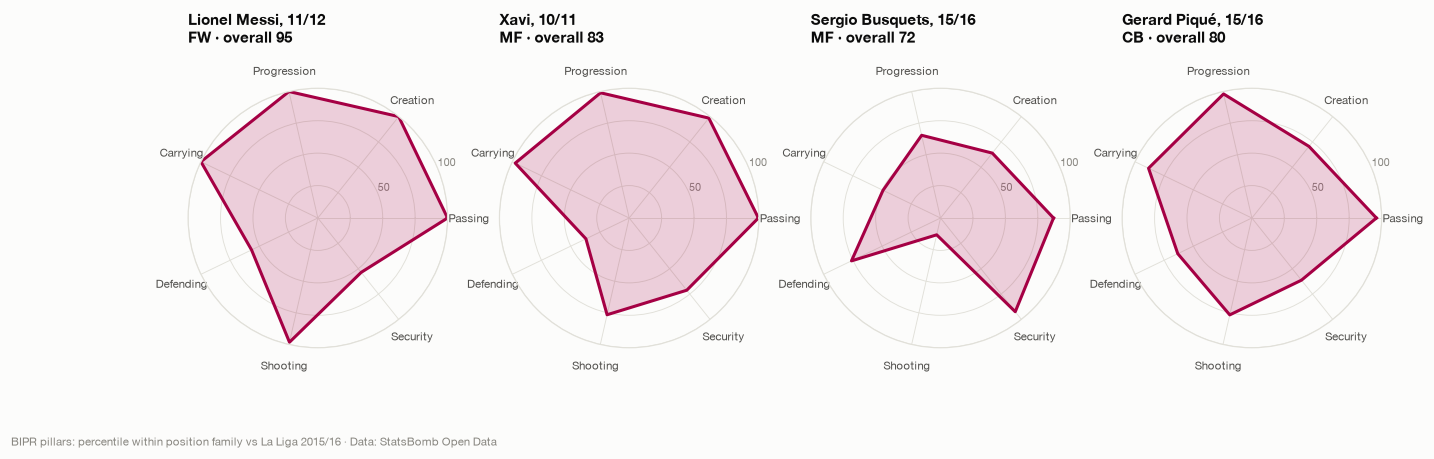

In [9]:
players = [("Lionel Messi", "2011/2012"), ("Xavi", "2010/2011"), ("Sergio Busquets", "2015/2016"),
           ("Gerard Piqué", "2015/2016")]
pillars = list(ratings.PILLARS)
angles = np.linspace(0, 2 * np.pi, len(pillars), endpoint=False).tolist()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.9), subplot_kw={"projection": "polar"})
for ax, (name, season) in zip(axes, players, strict=True):
    row = reliable.filter(pl.col("display_name") == name, pl.col("season") == season).row(0, named=True)
    vals = [row[f"pillar_{p}"] or 0 for p in pillars]
    ax.plot(angles + angles[:1], vals + vals[:1], color=style.BARCA, lw=2)
    ax.fill(angles + angles[:1], vals + vals[:1], color=style.BARCA, alpha=0.18)
    ax.set_xticks(angles, [p.title() for p in pillars], fontsize=7.5)
    ax.set_yticks([25, 50, 75, 100], ["", "50", "", "100"], fontsize=7, color=style.MUTED)
    ax.set_ylim(0, 100)
    ax.grid(color=style.GRID)
    ax.spines["polar"].set_color(style.GRID)
    ax.set_title(f"{name}, {season[2:4]}/{season[7:9]}\n{row['position_family']} · overall {row['overall']:.0f}",
                 fontsize=9.5, pad=14)
style.caption(axes[0], "BIPR pillars: percentile within position family vs La Liga 2015/16 · " + style.STATSBOMB_CREDIT)
style.savefig(fig, "10_bipr_profiles")
plt.show()

The profiles look like the players. Messi's 2011/12 is near-maximal on
every attacking pillar. Xavi's is a passer-progressor with little
defending. Piqué's is built on passing and progression, with shooting from
set pieces. **Busquets** shows the limit of event data: elite ball security
and passing, a middling overall, because the things he was famous for
(positioning, press resistance, occupying space) leave few events behind.
This is stated plainly on the player pages and in the limitations
document.

## 5. Are the ratings valid?

Three checks, none of which the ratings were tuned for.

**(a) Match ratings track match dominance.** Barcelona's average player
rating by result, and its correlation with the match xG difference:

In [10]:
team_avg = (
    pm.filter(pl.col("team") == "Barcelona", pl.col("match_rating").is_not_null(), pl.col("minutes") >= 30)
    .group_by("match_id").agg(pl.col("match_rating").mean().alias("avg_rating"))
    .join(store.features("team_match").filter(pl.col("team") == "Barcelona").select("match_id", "result", "xg_diff"),
          on="match_id")
)
team_avg.group_by("result").agg(pl.len().alias("matches"), pl.col("avg_rating").mean().alias("mean_rating")).sort("result", descending=True)

result,matches,mean_rating
str,u32,f64
"""W""",389,7.4
"""L""",52,7.3
"""D""",86,7.3


In [11]:
print("correlation of team average rating with xG difference:",
      round(team_avg.select(pl.corr("avg_rating", "xg_diff")).item(), 2))

correlation of team average rating with xG difference: 0.47


The average rating barely differs between wins and losses (7.4 vs 7.3).
That is informative rather than a failure. The ratings measure how players
performed with and without the ball, and Barcelona usually dominated even
the matches they lost. What the ratings do track is **dominance**: the
correlation with the match xG difference is about 0.47, and the result is
never an input.

**(b) Ratings are stable where talent is stable.** Year-to-year
correlation of a player's overall score:

In [12]:
yy = (
    reliable.sort("player_id", "season")
    .with_columns(pl.col("overall").shift(-1).over("player_id").alias("next"),
                  pl.col("season").shift(-1).over("player_id").alias("next_season"))
    .drop_nulls("next")
)
print(f"consecutive player-season pairs: {yy.height}, correlation: {yy.select(pl.corr('overall', 'next')).item():.2f}")

consecutive player-season pairs: 160, correlation: 0.77


**(c) Managers pick highly rated players.** Does a player's rating in one
season predict his share of Barcelona's league minutes the next season?

In [13]:
barca_min = pm.filter(pl.col("team") == "Barcelona").group_by("season").agg(pl.col("minutes").sum().alias("team_minutes"))
share = (
    player_ratings.filter(pl.col("team") == "Barcelona")
    .join(barca_min, on="season")
    .with_columns((pl.col("minutes") / pl.col("team_minutes") * 11).alias("share"))
    .sort("player_id", "season")
    .with_columns(pl.col("share").shift(-1).over("player_id").alias("next_share"))
    .filter(pl.col("rating_reliable"), pl.col("overall").is_not_null())
    .drop_nulls("next_share")
)
print(f"pairs: {share.height}, correlation of overall with next season's minute share: "
      f"{share.select(pl.corr('overall', 'next_share')).item():.2f}")

pairs: 182, correlation of overall with next season's minute share: 0.34


Year-to-year stability is high (player quality is persistent) and the
rating carries information about future selection. Both are what a useful
player metric should show. The lineup model (notebook 16) uses recent form
ratings as one input.

## 6. Form: rolling match ratings

The app's "Form" number is the minutes-weighted average match rating over
a player's last five appearances *before* the fixture being viewed. The
per-match ratings for Pedri's first season:

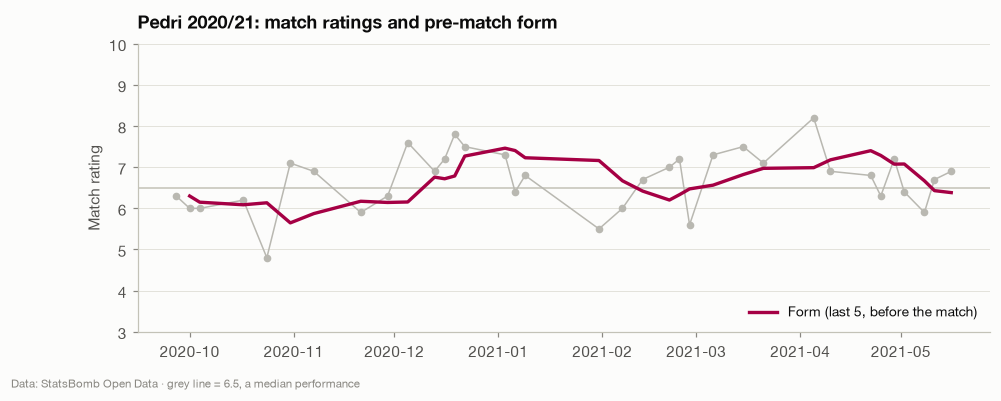

In [14]:
pedri = pm.filter(pl.col("display_name") == "Pedri", pl.col("match_rating").is_not_null()).sort("date")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axhline(6.5, color=style.AXIS, lw=1)
ax.plot(pedri["date"], pedri["match_rating"], color=style.NEUTRAL, lw=1, marker="o", ms=4)
w = pedri["minutes"].to_numpy()
r = pedri["match_rating"].to_numpy()
form = [np.average(r[max(0, i - 5):i], weights=w[max(0, i - 5):i]) if i else np.nan for i in range(len(r))]
ax.plot(pedri["date"], form, color=style.BARCA, lw=2.2, label="Form (last 5, before the match)")
ax.set_ylim(3, 10)
ax.set_ylabel("Match rating")
ax.set_title("Pedri 2020/21: match ratings and pre-match form")
ax.legend(loc="lower right")
style.caption(ax, style.STATSBOMB_CREDIT + " · grey line = 6.5, a median performance")
style.savefig(fig, "10_form")
plt.show()

## Summary

* **Elo** gives a calibrated team-strength rating (notebook 09).
* **xT** values ball progression, and reveals how much of Messi's value
  came from carrying.
* **BIPR** is transparent: seven pillars, published weights, a fixed
  reference population. It passes three validity checks it was not tuned
  for: it tracks match dominance (r ≈ 0.47 with xG difference), it is
  stable year to year (r ≈ 0.77) and it predicts next season's selection
  (r ≈ 0.34).
* **Known blind spot**: players whose value is off the ball (Busquets) are
  under-rated by any event-based rating. The app says so.

Methodology: `docs/model-methodology.md` § Ratings. Next: player workload
(`11_workload`).